<div dir="rtl" style="text-align:right">
<h1>InterviewPrep Agent – אבן דרך 2 (Milestone 2): תזמור ב-LangGraph</h1>
<p><b>מגישות:</b> דריה זוטובה ואלינה לוקיאנוב | <b>תחום:</b> Junior DevOps / Python</p>
<p>המחברת רק מריצה את הקוד שבמאגר (<code>src/graph.py</code>, <code>tests/</code>). היא רצה מתחילתה ועד סופה בקולאב נקי
(<b>Runtime → Run all</b>):</p>
<ol>
<li>שיבוט המאגר והתקנת <code>requirements.txt</code> (כולל גרסת LangGraph הנעולה)</li>
<li>טעינת מפתח Gemini מ-Colab Secrets – <b>רשות</b>. בלי מפתח הכול רץ עם המודל המדומה <code>MockLLM</code></li>
<li>הרצת כל הבדיקות בפקודה אחת (<code>pytest</code>)</li>
<li>תרשים הגרף</li>
<li>ארבעת המסלולים עם העקבות שלהם</li>
<li>עצירה וחידוש (<code>interrupt</code> + <code>Command(resume=...)</code>) והדגמת <code>thread_id</code> עם שתי שיחות נפרדות</li>
</ol>
</div>

<div dir="rtl" style="text-align:right">
<h2>שלב 1: שיבוט המאגר והתקנת התלויות</h2>
<p>התא משבט את המאגר <code>AlinaLu22/interview-prep-agent</code>. אם המחברת כבר רצה מתוך תיקיית המאגר, השיבוט מדולג.</p>
</div>

In [2]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/AlinaLu22/interview-prep-agent.git"  # the submitted repository
REPO_DIR = "interview-prep-agent"

if not Path("src/graph.py").exists():  # clean Colab: the code is not here yet
    if Path(REPO_DIR, "src", "graph.py").exists():
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only", "-q"])  # same session: take the latest version
    else:
        shutil.rmtree(REPO_DIR, ignore_errors=True)  # leftover of an earlier failed or empty clone
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
assert Path("src/graph.py").exists(), "No src/graph.py in the repository: upload the milestone 2 files to GitHub first"
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /content/interview-prep-agent/interview-prep-agent


In [3]:
!pip install -q -r requirements.txt

<div dir="rtl" style="text-align:right">
<h2>שלב 2 (רשות): מודל אמיתי דרך Colab Secrets</h2>
<p>כדי להריץ גם עם Gemini: בסרגל הצד (אייקון המפתח) מוסיפים Secret בשם <code>GEMINI_API_KEY</code> ומפעילים
<b>Notebook access</b>. בלי מפתח התא מדפיס שהמחברת רצה עם המודל המדומה. המפתח לא נשמר במאגר.</p>
</div>

In [4]:
try:
    from google.colab import userdata
    _key = userdata.get("GEMINI_API_KEY")
    if _key:
        os.environ["GEMINI_API_KEY"] = _key
except Exception:  # not in Colab, secret missing, or notebook access not granted
    pass

from src.llm import make_llm
llm = make_llm()
print("Model for the optional live step:", f"Gemini ({llm.model})" if llm.name == "gemini" else "MockLLM (mock model, no API key)")
print("All other steps always run with the mock model.")

Model for the optional live step: Gemini (gemini-3.5-flash)
All other steps always run with the mock model.


<div dir="rtl" style="text-align:right">
<h2>שלב 3: כל הבדיקות בפקודה אחת</h2>
<p>הבדיקות רצות תמיד עם מודל מדומה וכלים מדומים (מסומנים במפורש), בלי מפתח ובלי שירות חיצוני: הבדיקות של אבן דרך 1
וגם ארבעת המסלולים של הגרף, עצירה וחידוש, שתי שיחות נפרדות, שער האישור וה-Reducers.</p>
</div>

In [5]:
!python -m pytest -q

........................................................................ [ 64%]
.......................................                                  [100%]
111 passed in 9.93s


<div dir="rtl" style="text-align:right">
<h2>שלב 4: תרשים הגרף</h2>
<p>התרשים נוצר מהגרף המקומפל. קשתות מקווקוות הן קשתות מותנות. אותו תרשים נמצא ב-<code>docs/graph.mmd</code> וב-<code>docs/milestone2.md</code>.</p>
</div>

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	intake(intake)
	clarify(clarify)
	decide(decide)
	approval_gate(approval_gate)
	act(act)
	budget_stop(budget_stop)
	finish(finish)
	__end__([<p>__end__</p>]):::last
	__start__ --> intake;
	act -.-> decide;
	act -.-> finish;
	approval_gate --> act;
	budget_stop --> finish;
	clarify --> intake;
	decide -.-> act;
	decide -.-> approval_gate;
	decide -.-> budget_stop;
	decide -.-> finish;
	intake -.-> clarify;
	intake -.-> decide;
	intake -.-> finish;
	finish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



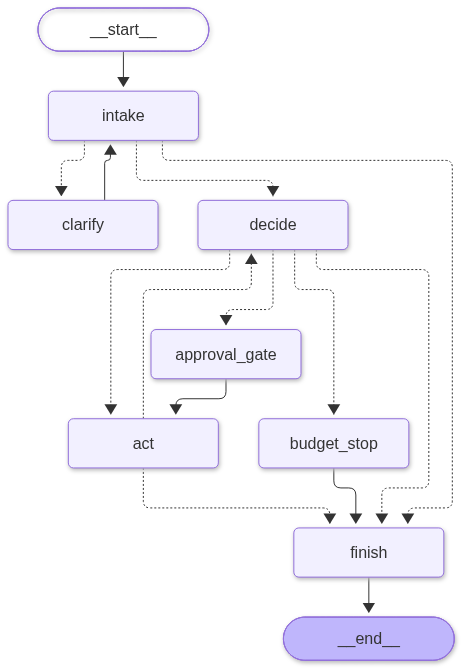

In [6]:
from IPython.display import Image, display
from src.graph import build_interview_graph, mermaid_diagram

print(mermaid_diagram())
try:  # drawing the picture needs internet access to mermaid.ink; the text above is always available
    display(Image(build_interview_graph().get_graph().draw_mermaid_png()))
except Exception as e:
    print("(picture skipped:", type(e).__name__, ")")

<div dir="rtl" style="text-align:right">
<h2>שלב 5: ארבעת המסלולים והעקבות שלהם</h2>
<p>הקוד מריץ את ארבעת המסלולים עם <code>MockLLM</code> ומפיק מחדש את קבצי העקבות ב-<code>docs/traces/</code>:
(1) נתונים קיימים, (2) מידע חסר – עצירה ובקשת הבהרה, (3) כשל זמני מדומה – ניסיון חוזר, (4) מיצוי תקציב הצעדים.
לכל מסלול מוצגים סדר הצמתים שרצו ורשימת קריאות הכלים.</p>
</div>

In [7]:
import json
from src.graph import generate_graph_traces

results = generate_graph_traces("docs/traces", diagram_path="docs/graph.mmd")
for name in ("route1_existing_data", "route2_missing_info_interrupt", "route3_transient_retry", "route4_step_budget"):
    trace = results[name]["trace"]
    print(f"\n=== {name}  (docs/traces/trace_graph_{name}.jsonl, {len(trace)} lines)")
    print("nodes:", " > ".join(e["node"] for e in trace if e["phase"] == "node"))
    for e in trace:
        if e["phase"] == "tool_call":
            print(f'  step {e["step"]:>2} | {e["tool"]:<21} | {e["status"]:<5} | attempts={e["attempts"]} {e["retries"] or ""}')
        elif e["phase"] in ("paused_at_interrupt", "checkpoint", "resume", "budget_stop", "done"):
            print(f'  {e["phase"]}: ' + ", ".join(f"{k}={v}" for k, v in e.items() if k != "phase"))


=== route1_existing_data  (docs/traces/trace_graph_route1_existing_data.jsonl, 44 lines)
nodes: intake > decide > act > decide > act > decide > act > decide > act > decide > act > decide > act > decide > act > decide > act > decide > approval_gate > act > decide > finish
  step  1 | parse_resume          | ok    | attempts=1 
  step  2 | parse_vacancy         | ok    | attempts=1 
  step  3 | compute_gap           | ok    | attempts=1 
  step  4 | search_question_bank  | ok    | attempts=1 
  step  5 | search_question_bank  | ok    | attempts=1 
  step  6 | search_question_bank  | ok    | attempts=1 
  step  7 | search_question_bank  | ok    | attempts=1 
  step  8 | search_question_bank  | ok    | attempts=1 
  step  9 | save_prep_plan        | ok    | attempts=1 
  done: status=DONE, stop_reason=model_final_answer, steps_used=10, max_steps=14, retries=0, question_count=10, saved=True

=== route2_missing_info_interrupt  (docs/traces/trace_graph_route2_missing_info_interrupt.jsonl, 51

<div dir="rtl" style="text-align:right">
<h2>שלב 6: עצירה וחידוש עם <code>interrupt</code></h2>
<p>קורות החיים קיימים אבל המודעה חסרה. הגרף עוצר בצומת <code>clarify</code>, והמצב נשמר ב-checkpointer תחת ה-<code>thread_id</code>.
אחר כך מחדשים את אותה שיחה עם <code>Command(resume=...)</code> דרך <b>אובייקט גרף חדש</b> שמשתף רק את ה-checkpointer.</p>
</div>

In [8]:
from langgraph.types import Command
from src.graph import (InMemorySaver, SAMPLE_RESUME, SAMPLE_VACANCY, initial_state, stream_run, thread_config)

saver = InMemorySaver()
THREAD = "colab-interrupt-demo"
graph_1 = build_interview_graph(checkpointer=saver)
log = []
snap = stream_run(graph_1, initial_state("daria", THREAD, SAMPLE_RESUME, ""), THREAD, log)
print("stopped, waiting at:", snap.next, "| tools called so far:", len(snap.values["tool_log"]))
print("the question to the user:", [e for e in log if e["phase"] == "paused_at_interrupt"][0]["interrupt"]["question"])

graph_2 = build_interview_graph(checkpointer=saver)  # a NEW graph object: the state lives in the checkpointer
snap = stream_run(graph_2, Command(resume=SAMPLE_VACANCY.strip()), THREAD, log)
print("resumed -> status:", snap.values["status"], "| steps:", snap.values["step"], "| waiting at:", snap.next)
print("gap:", snap.values["gap_json"])

stopped, waiting at: ('clarify',) | tools called so far: 0
the question to the user: Some input is missing or too short. Please provide: vacancy_text
resumed -> status: DONE | steps: 10 | waiting at: ()
gap: {'matched': ['python', 'linux'], 'missing': ['docker', 'ci/cd'], 'weak': []}


<div dir="rtl" style="text-align:right">
<h2>שלב 7: <code>thread_id</code> – שתי שיחות נפרדות על checkpointer אחד</h2>
<p>שיחה A נעצרת ב-<code>clarify</code>; בזמן העצירה שיחה B (משתמשת אחרת, קורות חיים אחרים) רצה עד הסוף ושיחה A לא משתנה.
אחר כך A מחודשת ומסתיימת. התוצאות והיסטוריית ה-checkpoints נפרדות לכל שיחה. אותה בדיקה רצה ב-<code>tests/test_graph.py</code>.</p>
</div>

In [9]:
from src.graph import run_checkpointer_threads_demo

trace, snaps = run_checkpointer_threads_demo()
iso = [e for e in trace if e["phase"] == "isolation_check"][0]
print("while A was stopped: A waiting at", iso["thread_A_still_waiting_at"], "| A gap =", iso["thread_A_gap"],
      "| B status =", iso["thread_B_status"])
summary = [e for e in trace if e["phase"] == "threads_summary"][0]
for key in ("thread_A", "thread_B"):
    s = summary[key]
    print(f'{key}: status={s["status"]} | missing={s["gap"]["missing"]} | tools={len(s["tools_called"])} | checkpoints={s["checkpoints"]}')

while A was stopped: A waiting at ['clarify'] | A gap = None | B status = DONE
thread_A: status=DONE | missing=['docker', 'ci/cd'] | tools=9 | checkpoints=26
thread_B: status=DONE | missing=['linux'] | tools=10 | checkpoints=26


<div dir="rtl" style="text-align:right">
<h2>שלב 8 (רשות): הגרף עם Gemini אמיתי</h2>
<p>רץ רק כשמוגדר מפתח. עם מפתח חינמי (5 בקשות לדקה) השלב לוקח כמה דקות. האישור לפני שמירה נדחה (<code>user_approval=False</code>), ולכן לא נשמר קובץ.
בלי מפתח השלב מדולג.</p>
</div>

In [10]:
if llm.name == "gemini":
    try:
        live_log = []
        live = stream_run(build_interview_graph(llm=llm), initial_state("demo-user", "colab-live", SAMPLE_RESUME,
                          SAMPLE_VACANCY, user_approval=False), "colab-live", live_log)
        print("status:", live.values["status"])
        for e in live_log:
            if e["phase"] == "tool_call":
                print(f'step {e["step"]:>2} | {e["decided_by"]} -> {e["tool"]} | {e["status"]}')
        print("\n" + live.values["answer"])
    except Exception as e:  # e.g. quota or model name: show the error and finish
        print(f"Gemini run failed: {type(e).__name__}: {e}"[:1500])
else:
    print("No GEMINI_API_KEY: this optional step is skipped (everything above ran with the mock model).")

[gemini] 503 server error - waiting 5s, then retry 2/6
[gemini] 503 server error - waiting 10s, then retry 3/6
[gemini] 503 server error - waiting 20s, then retry 4/6
[gemini] 503 server error - waiting 40s, then retry 5/6
[gemini] 503 server error - waiting 60s, then retry 6/6
Gemini run failed: ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
